# Lab Report - Interpolation

### Problem Statement: 
##### Choose a cambered airfoil NACA-abcd. For a given number of points on the airfoil geometry (N), reconstruct a smooth airfoil surface.

##### Stages: 
1) Use a random number generator in NumPy to choose the maximum camber, the location of maximum camber and the percentage of thickness to chord.
2) Write a function to plot a cambered airfoil.
3) Write a function "Lagrng". Use the function 'Lagrng()' to reconstruct the airfoil.
4) Plot the original airfoil and the reconstructed one.
5) Quantify the error (max, RMS) between the true and reconstructed results.
6) Document how the results can be improved by choosing the spacing between data points.
7) Reconstruct the airfoil using cubic splines and quantify the errors. This requires writing a Python function for cubic spline interpolation.

### Approach and numerical method

#### 1) Random Number Generator:
The random number option in NumPy is used to create random numbers for the NACA airfoil.\
    In the case of the NACA 4-digit series, we need 3 such numbers, as the airfoil nomenclature uses\
        **1st** digit for max camber as a percentage of the chord,\
        **2nd** digit for location of max camber from the leading edge in tenths of chord,\
        **last 2** digits indicating the thickness as a percentage of the chord

     The random numbers were generated and stored in the respective variables, namely
   
 ```python
#For ease of use
m = Max_camber
p = Max_c_location
t = Thickness
```

    

#### 2) Writing a function to plot a cambered airfoil.

    If we think in reverse chronology, we need the X, Y coordinates, which would start from the leading edge of the airfoil/
    and trace the curve to the trailing edge through the upper surface, then back to the leading edge via the lower surface in one go.

   1) We need coordinates of x,y for the upper and lower surfaces. Then we need to concatenate them after flipping the coordinates of the lower surface
   2) Since the airfoil has a camber line, we need a function that evaluates Y_c (camber line) for the given value of x
   3) Then, again, a secondary function that evaluates the change in Y due to Y_c.

    


##### Thickness Distribution

$$y_t=5t\left(0.2969\sqrt{x}-0.1260x-0.3516x^2+0.2843x^3-0.1015x^4\right)$$

##### Mean Camber Line

$0\leq x\leq p$
$$y_c=\frac{m}{p^2}\left(2px-x^2\right)$$

$p\leq x\leq1$
$$y_c=\frac{m}{(1-p)^2}\left(1-2p+2px-x^2\right)$$

##### Camber Line Slope

For $0\leq x\leq p$
$$\frac{dy_c}{dx}=\frac{2m}{p^2}(p-x)$$

For $p\leq x\leq1$
$$\frac{dy_c}{dx}=\frac{2m}{(1-p)^2}(p-x)$$

##### Surface Coordinates

$$\theta=\tan^{-1}\left(\frac{dy_c}{dx}\right)$$

$$x_u=x-y_t\sin\theta$$
$$y_u=y_c+y_t\cos\theta$$

$$x_l=x+y_t\sin\theta$$
$$y_l=y_c-y_t\cos\theta$$

#### 3) Writing the interpolation function lagrng()

##### Lagrange Interpolation Polynomial

Given $n$ data points $(x_i,y_i)$, the Lagrange polynomial is

$$P(x)=\sum_{i=0}^{n-1}y_iL_i(x)$$

where the Lagrange basis polynomial is

$$L_i(x)=\prod_{\substack{j=0\\j\neq i}}^{n-1}\frac{x-x_j}{x_i-x_j}$$


#### Using a random number generator to create NACA-abcd Airfoil.

In [1]:
#generating 3 random numbers for the NACA airfoil
import numpy as np

Max_camber = np.random.randint(2,10)
Max_c_location = np.random.randint(3,7)
Thickness = np.random.randint(10,15)

#print(Max_camber,Max_c_location,Thickness)

Max_camber = Max_camber/100
Max_c_location = Max_c_location/10
Thickness = Thickness/100

print(Max_camber,Max_c_location,Thickness)

#For ease of use
m = Max_camber
p = Max_c_location
t = Thickness

0.05 0.5 0.1


### Writing a function to plot a Cambered NACA Airfoil

In [2]:

x = np.linspace(0, 1, 201) #creating n points for the x axis
#print(x)

# Corresponding y values for the generated x values.
y_t = 5*t*(0.2969*(x**0.5) - 0.1260*(x) - 0.3516*(x**2) + 0.2843*(x**3) - 0.1036*(x**4)) # y_t is thickness value

# evaluating y values for the x to plot the camber line
y_c = np.where(x <= p, (m/p**2) * (2*p*x - x**2), (m/(1-p)**2) * ((1 - 2*p) + 2*p*x - x**2))
#print(y_c)

# Evaluating x,y values for the upper and lower surfaces.
# So that the increment in y value due to the camber is perpendicular to the surface and not just along the y-axis 
d_yc = np.where(x <= p, (2*m/p**2) * (p - x),(2*m/(1-p)**2) * (p - x) )

Theta = np.arctan(d_yc)

x_u = x - y_t*np.sin(Theta)
y_u = y_c + y_t*np.cos(Theta)
x_l = x + y_t*np.sin(Theta)
y_l = y_c - y_t*np.cos(Theta)
#print(x_u,x_l)

x_l = np.flip(x_l)
y_l = np.flip(y_l)
#print(x_l)
X = np.concatenate([x_u,x_l])
Y = np.concatenate([y_u,y_l])
print(X[200],X[401])
#print(X,Y)

1.0 0.0


### Plotting the NACA airfoil using the written function

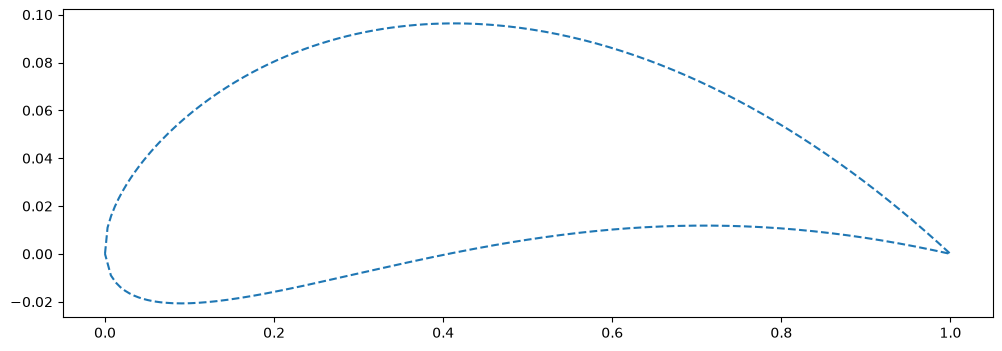

In [3]:

import matplotlib.pyplot as mp
mp.figure(figsize=(12, 4))
mp.plot(X,Y, '--')
mp.show()



### Writing a Lagrange function to perform interpolation

In [4]:

def Lagrng(x,y,n,a):
    sum = 0
    for i in range(0,n):
        product = y[i]
        for j in range(0,n):
            if i!= j:
                product = product*(a - x[j])/(x[i] - x[j])
        sum = sum + product
    return(sum)

### Reconstructing the airfoil using Lagrng Function


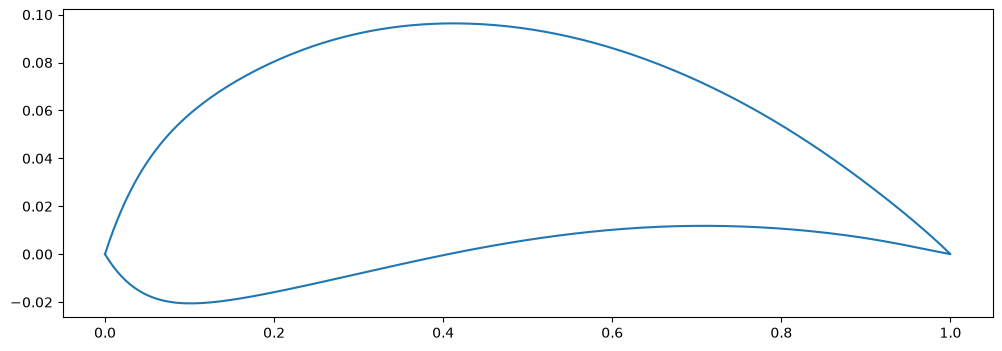

In [5]:


#x_u = np.array([X[0],X[10],X[20],X[30],X[40],X[60],X[80],X[100],X[120],X[140],X[180],X[200]])
#y_u = np.array([Y[0],Y[10],Y[20],Y[30],Y[40],Y[60],Y[80],Y[100],Y[120],Y[140],Y[180],Y[200]])

#x_l = np.array([X[201],X[220],X[250],X[275],X[300],X[325],X[350],X[375],X[380],X[390],X[400],X[401]])
#y_l = np.array([Y[201],Y[220],Y[250],Y[275],Y[300],Y[325],Y[350],Y[375],Y[380],Y[390],Y[400],Y[401]])

# x_upper = X[np.arange(0,200,40)]
# y_upper = Y[np.arange(0,200,40)]
# x_lower = X[np.arange(201,401,40)]
# y_lower = Y[np.arange(201,401,40)]

x_upper = np.array([X[0],X[20],X[40],X[60],X[80],X[100],X[120],X[140],X[160],X[180],X[200]])
y_upper = np.array([Y[0],Y[20],Y[40],Y[60],Y[80],Y[100],Y[120],Y[140],Y[160],Y[180],Y[200]])

x_lower = np.array([X[201],X[221],X[241],X[261],X[281],X[301],X[321],X[341],X[361],X[381],X[401]])
y_lower = np.array([Y[201],Y[221],Y[241],Y[261],Y[281],Y[301],Y[321],Y[341],Y[361],Y[381],Y[401]])

Xupper= np.linspace(0,1,201)
Xlower= np.flip(Xupper)

Yupper= Lagrng(x_upper,y_upper,11,Xupper)
Ylower= Lagrng(x_lower,y_lower,11,Xlower)

X_a= np.concatenate([Xupper,Xlower])
Y_a= np.concatenate([Yupper,Ylower])
mp.figure(figsize=(12, 4))
mp.plot(X_a,Y_a)
#mp.plot(Xupper,Yupper,'--')
#mp.plot(Xlower,Ylower,'--')
#print(Xupper,Yupper)
#print(Y_a)

X_test= np.concatenate([x_upper,x_lower])
Y_test= np.concatenate([y_upper,y_lower])
#mp.plot(X_test,Y_test)
#mp.plot(x_u,y_u,'o')

### calculating the error between the actual and the reconstructed airfoil

In [6]:
Y_difference = Y - Y_a
# Y_difference = np.abs(Y_difference)
# Ymax_index = np.argmax(Y_difference)
# Ymax = Y[Ymax_index]

max_error = np.max(np.abs(Y_difference))
print("Maximum Error % = ",max_error*100)

rms_error = np.sqrt(np.mean(Y_difference ** 2))
print("RMS Error % = ",rms_error*100)

#print(Y_diff_max)
#Max_percentage = (Y_diff_max/Ymax)*100
#print(Max_percentage)

Maximum Error % =  0.6697148160066108
RMS Error % =  0.11221158722540663


### Comparing the original and the reconstructed airfoil 

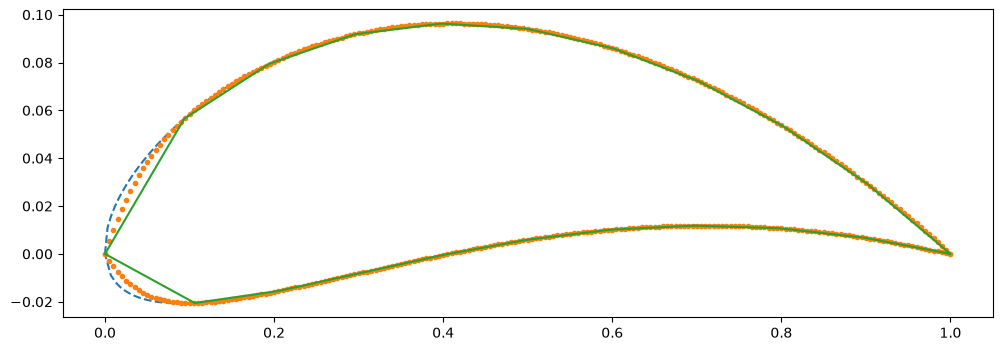

In [7]:
mp.figure(figsize=(12, 4))
mp.plot(X,Y, '--')
mp.plot(X_a,Y_a,'.')
mp.plot(X_test,Y_test)
mp.show()
